# LightGBM feature experiments

Same model, same hyperparameters, same splits as the baseline. **Only the input features change.**
Each experiment = a set of feature groups from `lightgbm_features.GROUP_COLS`.
Run on `val` only. Use `test` once, at the end, for the final chosen feature set.

In [ ]:
import sys, time
sys.path.insert(0, "../src")
import pandas as pd
from remy.splits import RollingSplits, SPLIT_DIR
from remy.model.lightgbm_features import LightGBM, GROUP_COLS, BASELINE_GROUPS
from remy.evaluate import evaluate_quarter

splits = RollingSplits()
SPLIT = "val"
STRIDE = 1          # 1 = all 16 quarters; use 4 for quick exploration
quarters = splits.evaluation_quarters(SPLIT)[::STRIDE]
METRICS = ["NDCG", "HR@10", "HR@100", "Recall@10", "Recall@100"]
print({g: len(c) for g, c in GROUP_COLS.items()})

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


{'user_base': 3, 'tags': 0, 'user_activity': 5, 'user_taste': 5, 'recipe_pop': 7, 'recipe_rating': 2, 'recipe_static': 5, 'inter_tag': 2, 'inter_diff': 4}


## Experiment definitions
`baseline` should reproduce your earlier numbers (sanity check). Then add one group at a time, then combine.

In [2]:
B = BASELINE_GROUPS  # ("user_base", "tags")
EXPERIMENTS = {
    "baseline":              B,
    "+user_activity":        B + ("user_activity",),
    "+user_taste":           B + ("user_taste",),
    "+recipe_pop":           B + ("recipe_pop",),
    "+recipe_rating":        B + ("recipe_rating",),
    "+recipe_static":        B + ("recipe_static",),
    "+inter_tag":            B + ("user_taste", "inter_tag"),   # interactions need taste profile
    "+inter_diff":           B + ("user_taste", "recipe_pop", "recipe_static", "inter_diff"),
    "all_user+recipe":       B + ("user_activity", "user_taste", "recipe_pop", "recipe_rating", "recipe_static"),
    "all":                   tuple(GROUP_COLS),
}

In [4]:
def run(groups, **model_kwargs):
    rows = []
    for i, q in enumerate(quarters):
        t0 = time.perf_counter()
        m = LightGBM(feature_groups=groups, **model_kwargs)
        m.fit(q.history, recipes=q.recipes,
              training_quarters=splits.training_quarters(q.start), cutoff=q.start)
        t_fit = time.perf_counter() - t0
        pos_users = q.outcomes.loc[q.outcomes["rating"] == 5, "user_id"].unique()
        recs = m.recommend_batch(pos_users, k=None)
        rows.append(evaluate_quarter(q, m.ranking_, m.seen_, recs))
        print(f"  quarter {i+1}/{len(quarters)} {q.start.date()}: "
              f"fit {t_fit:.0f}s, total {time.perf_counter()-t0:.0f}s", flush=True)
    return pd.DataFrame(rows), m

results, per_quarter, models = {}, {}, {}
for name, groups in EXPERIMENTS.items():
    t0 = time.perf_counter()
    df, models[name] = run(groups)
    per_quarter[name] = df
    results[name] = df[METRICS].mean()
    df.to_csv(SPLIT_DIR / f"lgbm_feat_{SPLIT}_{name.replace('+','plus_')}.csv", index=False)
    print(f"{name:20s} NDCG={results[name]['NDCG']:.4f}  HR@100={results[name]['HR@100']:.4f}  "
          f"({(time.perf_counter()-t0)/60:.1f} min)")

  quarter 1/16 2007-01-01: fit 22s, total 49s
  quarter 2/16 2007-04-01: fit 30s, total 64s
  quarter 3/16 2007-07-01: fit 30s, total 69s
  quarter 4/16 2007-10-01: fit 27s, total 61s
  quarter 5/16 2008-01-01: fit 24s, total 64s
  quarter 6/16 2008-04-01: fit 27s, total 63s
  quarter 7/16 2008-07-01: fit 30s, total 68s
  quarter 8/16 2008-10-01: fit 33s, total 77s
  quarter 9/16 2009-01-01: fit 36s, total 89s
  quarter 10/16 2009-04-01: fit 46s, total 89s
  quarter 11/16 2009-07-01: fit 44s, total 89s
  quarter 12/16 2009-10-01: fit 51s, total 104s
  quarter 13/16 2010-01-01: fit 52s, total 104s
  quarter 14/16 2010-04-01: fit 54s, total 99s
  quarter 15/16 2010-07-01: fit 58s, total 90s
  quarter 16/16 2010-10-01: fit 59s, total 90s
baseline             NDCG=0.1214  HR@100=0.1341  (21.1 min)
  quarter 1/16 2007-01-01: fit 18s, total 47s
  quarter 2/16 2007-04-01: fit 18s, total 47s
  quarter 3/16 2007-07-01: fit 22s, total 55s
  quarter 4/16 2007-10-01: fit 24s, total 63s
  quarter 5

In [5]:
summary = pd.DataFrame(results).T.round(4)
summary["dNDCG_vs_baseline"] = (summary["NDCG"] - summary.loc["baseline", "NDCG"]).round(4)
summary.to_csv(SPLIT_DIR / f"lgbm_feature_experiments_{SPLIT}.csv")
summary

,NDCG,HR@10,HR@100,Recall@10,Recall@100,dNDCG_vs_baseline
baseline,0.1214,0.0297,0.1341,0.0118,0.0559,0.0000
+user_activity,0.1215,0.0297,0.1346,0.0121,0.0561,0.0001
+user_taste,0.1213,0.0283,0.1315,0.0114,0.0542,-0.0001
+recipe_pop,0.1259,0.0433,0.1727,0.0167,0.0763,0.0045
+recipe_rating,0.1188,0.0198,0.1037,0.0075,0.0406,-0.0026
+recipe_static,0.1220,0.0306,0.1433,0.0124,0.0602,0.0006
+inter_tag,0.1218,0.0294,0.1388,0.0111,0.0569,0.0004
+inter_diff,0.1261,0.0424,0.1742,0.0165,0.0769,0.0047
all_user+recipe,0.1263,0.0424,0.1730,0.0162,0.0764,0.0049
all,0.1267,0.0431,0.1798,0.0167,0.0791,0.0053


## Per-quarter comparison
A feature set is only convincing if it wins in most quarters, not just on the mean.

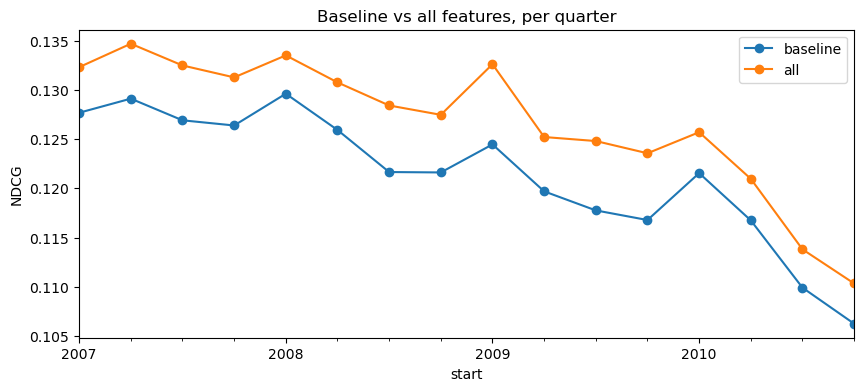

'all' beats baseline NDCG in 100% of quarters


In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["baseline", "all"]:
    per_quarter[name].plot(x="start", y="NDCG", ax=ax, label=name, marker="o")
ax.set(ylabel="NDCG", title="Baseline vs all features, per quarter"); plt.show()

wins = (per_quarter["all"]["NDCG"] > per_quarter["baseline"]["NDCG"]).mean()
print(f"'all' beats baseline NDCG in {wins:.0%} of quarters")

## Feature importance (last quarter's model, all features)

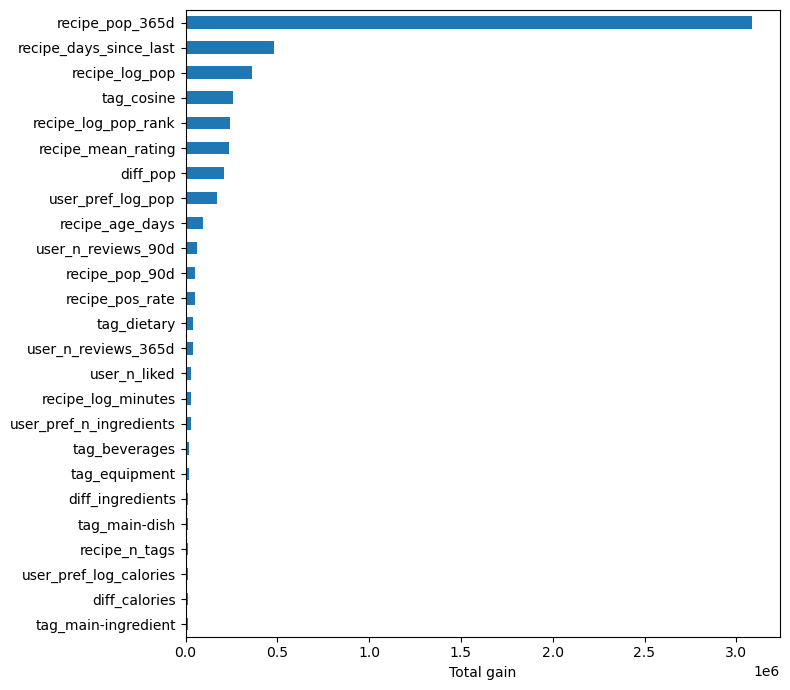

In [7]:
m = models["all"]
imp = pd.Series(m.model_.feature_importance("gain"), index=m.feature_names_).sort_values(ascending=False).head(25)
imp.iloc[::-1].plot.barh(figsize=(8, 7)); plt.xlabel("Total gain"); plt.tight_layout(); plt.show()